# Exploring the Hill force–velocity curve

Read [Chapter 1](../docs/models/Hill.md) first. This notebook illustrates
$$v(F)=\frac{b(F_0-F)}{F+a}.$$

**Scientific source:** [Hill (1938)](https://doi.org/10.1098/rspb.1938.0050),
printed p. 161, equations (1)–(2); see [bibliographic and source notes](../REFERENCES.md).
The original work concerns skeletal muscle. These plots do not validate a cardiac model.

**Status:** numerical exploration of a formally defined function. All parameter
values below are synthetic choices for arithmetic and visualization, not data,
fits, or recommended physiological values. Python floating-point calculations
are separate from the exact real-number proofs in [Hill.lean](../CardioLean/Contraction/Hill.lean).

Use “Restart kernel and run all” after editing. [Setup and execution instructions](README.md).

## 1. Choose units and the domain

Use newtons (N) for `F`, `F₀`, and `a`, and metres per second (m/s) for `v` and `b`.
Python does not enforce dimensions. We assume `F₀ ≥ 0`, `a > 0`, `b ≥ 0`, and
`0 ≤ F ≤ F₀`; strict decrease additionally requires `b > 0`.

The function below deliberately rejects inputs outside this learning domain.
It also rejects the singular point, unlike Lean's total real division. This
wrapper is an exploration convenience, not a translation of the full Lean function.

In [1]:
import math
from pathlib import Path
import matplotlib.pyplot as plt


def hill_velocity(force, *, isometric_force, a, b):
    values = (force, isometric_force, a, b)
    if not all(math.isfinite(value) for value in values):
        raise ValueError("Use finite parameter and force values.")
    if isometric_force < 0 or a <= 0 or b < 0:
        raise ValueError("Require F0 >= 0, a > 0, and b >= 0.")
    if not 0 <= force <= isometric_force:
        raise ValueError("Require 0 <= force <= F0.")
    return b * (isometric_force - force) / (force + a)


# Illustrative values only; units stated in the variable names.
F0_N = 1.0
a_N = 0.25
b_m_per_s = 0.1
forces_N = [F0_N * i / 100 for i in range(101)]
print(f"F0={F0_N} N, a={a_N} N, b={b_m_per_s} m/s (synthetic)")

F0=1.0 N, a=0.25 N, b=0.1 m/s (synthetic)


## 2. Calculate a few points

Before running the next cell, predict the velocity at zero load, half the
isometric force, and the isometric force. At half force, the worked example in
the chapter gives approximately `0.0667 m/s`. At `F₀`, the numerator is zero.
Zero load is a mathematical endpoint; this notebook does not simulate an experimental release.

In [2]:
print("Force (N)    Velocity (m/s)")
for force in (0.0, F0_N / 2, F0_N):
    value = hill_velocity(force, isometric_force=F0_N, a=a_N, b=b_m_per_s)
    print(f"{force:9.2f}    {value:14.6f}")

Force (N)    Velocity (m/s)
     0.00          0.400000
     0.50          0.066667
     1.00          0.000000


## 3. Change one parameter at a time

The left panel varies the force offset `a`, keeping `F₀` and `b` fixed.
The right panel varies `b`, keeping `F₀` and `a` fixed; `b=0` includes the
allowed degenerate curve. Think about numerator and denominator before interpreting each curve.
The horizontal axis is force, **not time**. Lines join samples of the formula.

The next cell also exports the figure used in the chapter. Running the notebook
will replace that generated image with the current parameter choices.

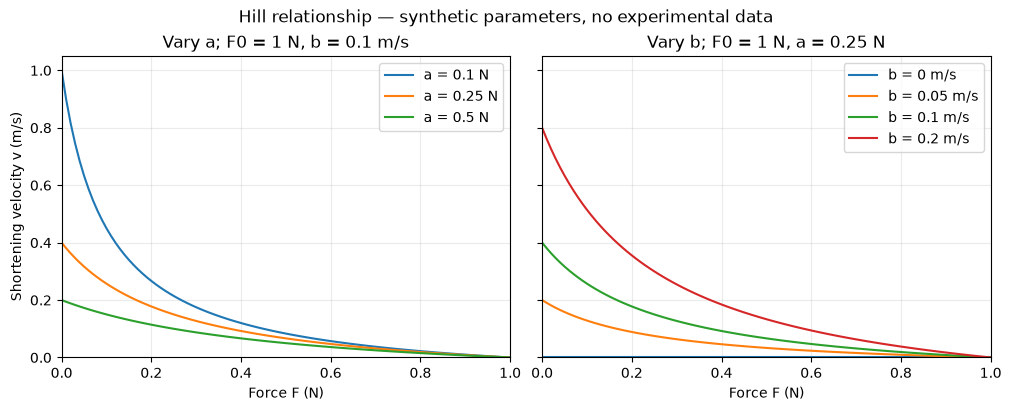

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
for offset in (0.1, 0.25, 0.5):
    values = [hill_velocity(f, isometric_force=F0_N, a=offset, b=b_m_per_s)
              for f in forces_N]
    axes[0].plot(forces_N, values, label=f"a = {offset:g} N")
axes[0].set_title(f"Vary a; F0 = {F0_N:g} N, b = {b_m_per_s:g} m/s")

for speed in (0.0, 0.05, 0.1, 0.2):
    values = [hill_velocity(f, isometric_force=F0_N, a=a_N, b=speed)
              for f in forces_N]
    axes[1].plot(forces_N, values, label=f"b = {speed:g} m/s")
axes[1].set_title(f"Vary b; F0 = {F0_N:g} N, a = {a_N:g} N")

for ax in axes:
    ax.set_xlabel("Force F (N)")
    ax.set_xlim(0, F0_N)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Shortening velocity v (m/s)")
fig.suptitle("Hill relationship — synthetic parameters, no experimental data")

repo_root = Path.cwd() if Path("CardioLean.lean").exists() else Path.cwd().parent
if not (repo_root / "CardioLean.lean").is_file():
    raise RuntimeError("Run from the repository root or notebooks directory.")
figure_path = repo_root / "docs/assets/hill-force-velocity.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, metadata={"Software": "CardioLean Hill notebook"})
plt.show()

## 4. Numerical observations and their limits

The following assertions inspect 101 samples for the baseline parameters.
They check nonnegativity, ordering, and the residual of the original equation.
`math.isclose` accepts small floating-point rounding errors. Passing these checks
is **not** a proof for every real force or every admissible parameter choice.
The Lean theorems state those universal results under explicit hypotheses.

In [4]:
velocities = [hill_velocity(f, isometric_force=F0_N, a=a_N, b=b_m_per_s)
              for f in forces_N]
assert all(v >= 0 for v in velocities)
assert all(v_next <= v for v, v_next in zip(velocities, velocities[1:]))
assert velocities[-1] == 0.0
residuals = [(f + a_N) * (v + b_m_per_s) - (F0_N + a_N) * b_m_per_s
             for f, v in zip(forces_N, velocities)]
assert all(math.isclose(residual, 0.0, abs_tol=1e-12) for residual in residuals)
print(f"Checked {len(forces_N)} baseline samples.")
print(f"Largest absolute equation residual: {max(map(abs, residuals)):.3g} N*m/s")
print("Finite numerical checks passed; no new Lean theorem was proved.")

Checked 101 baseline samples.
Largest absolute equation residual: 2.78e-17 N*m/s
Finite numerical checks passed; no new Lean theorem was proved.


## 5. Connect the observation to a proof

In namespace `CardioLean.Contraction.Hill`:

| Lean theorem | What the notebook illustrates |
|---|---|
| `denominator_pos` | `F+a` stays positive in the chosen domain |
| `equation_iff_velocity` | The quotient solves the product equation when `F+a ≠ 0` |
| `velocity_nonneg` | Admissible velocities are nonnegative |
| `velocity_at_isometric` | The curve reaches zero at `F₀` |
| `velocity_antitoneOn` | Increasing force cannot increase velocity |
| `velocity_strictAntiOn` | With `b>0`, distinct ordered forces have strictly ordered velocities |

The last two results come from the sign of `b(F₀+a)(F₂−F₁)` after comparing
fractions with positive denominators. Read the proof walkthrough in the chapter.

## Questions to answer yourself

1. Why does `b=0` produce a horizontal curve? Which theorem still applies?
2. Why is division by `F+a` legitimate in this domain?
3. Predict the zero-load velocity after doubling `b`, then check your prediction.
4. Can you derive `v(0)=bF₀/a` and the upper bound on velocity? These remain
   proposed Lean exercises, not additional formal results in this notebook.
5. Which experimental evidence would you need before interpreting any curve as cardiac behavior?

Record your own predictions, observations, and corrections in
[the journal scaffold](../journal/002-hill-model.md).